1. RESEARCH QUESTIONS
1. Do the three penguin species have different bill and flipper measurements?
2. How does body mass vary across different islands and sexes?
3. Is there a relationship between bill length and bill depth?
4. Do male penguins have higher body mass than female penguins?
5. Are there outliers or unusual values in the dataset?

2. DATASET EXPLORATION

Dataset Imported Successfully!

First Five Rows:
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   

   body_mass_g     sex  
0       3750.0    Male  
1       3800.0  Female  
2       3250.0  Female  
3          NaN     NaN  
4       34

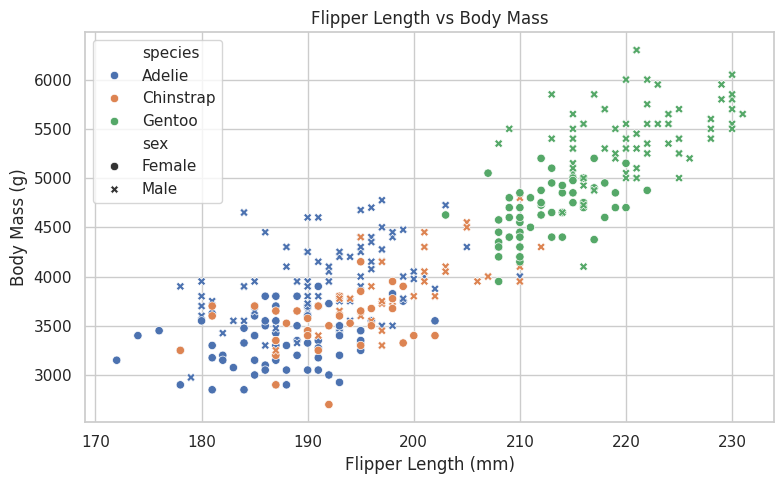

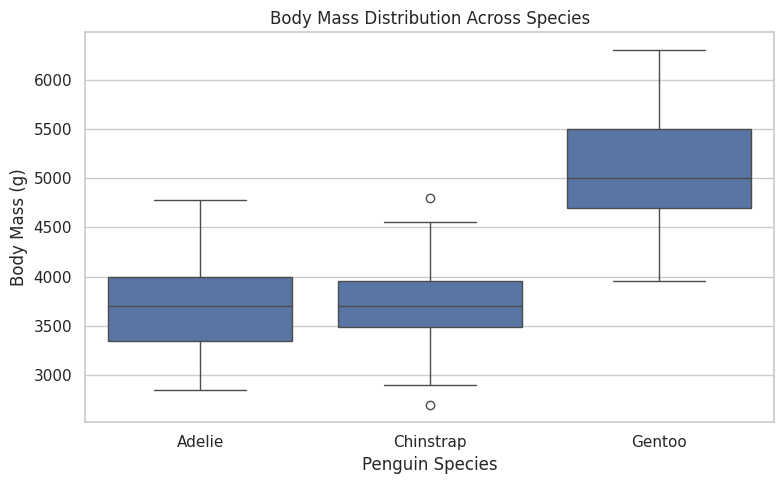

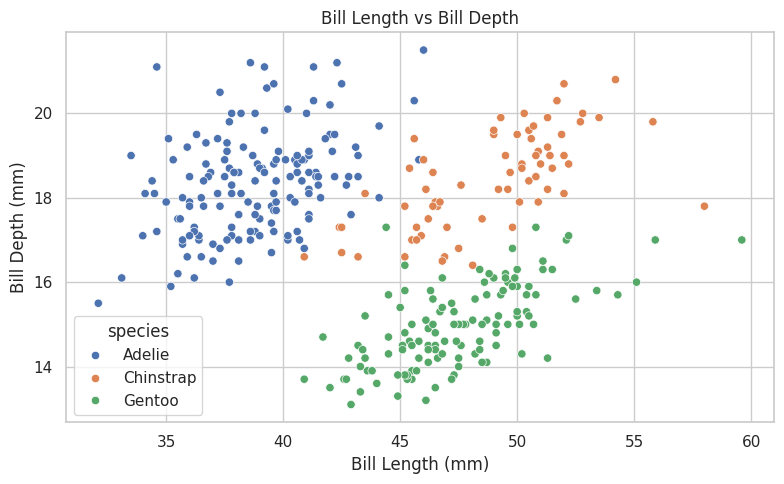

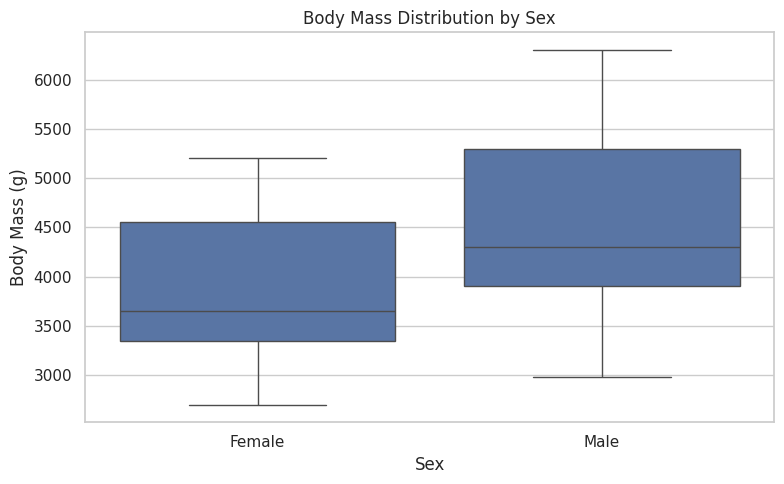


7. HYPOTHESIS TESTING

Independent Two-Sample Welch's t-Test
Null Hypothesis (H0):
Mean body mass of Adelie and Gentoo penguins is equal.

Alternative Hypothesis (H1):
Mean body mass of Adelie and Gentoo penguins is different.

Adelie Average Body Mass: 3700.66
Gentoo Average Body Mass: 5075.4

t-statistic: -23.5509
p-value: 1.3783855219453791e-65

Result: Reject the Null Hypothesis.
There is a statistically significant difference in body mass.

8. FINAL DATA VALIDATION

Final Dataset Shape:
(344, 7)

Final Missing Values:
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64

Final Duplicate Records:
0

Final Data Types:
species              category
island               category
bill_length_mm        float64
bill_depth_mm         float64
flipper_length_mm     float64
body_mass_g           float64
sex                  category
dtype: object

Cleaned Dataset Saved Su

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")


# ==========================================================
# 1. MEANINGFUL RESEARCH QUESTIONS
# ==========================================================

print("=" * 60)
print("1. RESEARCH QUESTIONS")
print("=" * 60)

research_questions = [
    "1. Do the three penguin species have different bill and flipper measurements?",
    "2. How does body mass vary across different islands and sexes?",
    "3. Is there a relationship between bill length and bill depth?",
    "4. Do male penguins have higher body mass than female penguins?",
    "5. Are there outliers or unusual values in the dataset?"
]

for question in research_questions:
    print(question)


# ==========================================================
# 2. IMPORT DATASET AND EXPLORE ITS STRUCTURE
# ==========================================================

print("\n" + "=" * 60)
print("2. DATASET EXPLORATION")
print("=" * 60)

df = sns.load_dataset("penguins")

print("\nDataset Imported Successfully!")

print("\nFirst Five Rows:")
print(df.head())

print("\nNumber of Rows and Columns:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nData Types:")
print(df.dtypes)


# ==========================================================
# 3. IDENTIFY DATA ISSUES AND OUTLIERS
# ==========================================================

print("\n" + "=" * 60)
print("3. DATA QUALITY CHECK")
print("=" * 60)

print("\nMissing Values Before Cleaning:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nUnique Species:")
print(df["species"].unique())

print("\nUnique Islands:")
print(df["island"].unique())

print("\nUnique Sexes:")
print(df["sex"].unique())

numeric_columns = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

print("\nChecking Invalid Numerical Values:")

for col in numeric_columns:
    invalid = (df[col] <= 0).sum()
    print(f"{col}: {invalid} invalid values")

# Detect potential outliers using IQR

print("\nOutlier Detection Using IQR:")

for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"{col}: {len(outliers)} potential outliers")


# ==========================================================
# 4. DATA CLEANING AND PREPROCESSING
# ==========================================================

print("\n" + "=" * 60)
print("4. DATA CLEANING")
print("=" * 60)

# Remove duplicate records
df = df.drop_duplicates()

# Standardize categorical entries
categorical_columns = ["species", "island", "sex"]

for col in categorical_columns:
    df[col] = df[col].astype("string").str.strip().str.title()

# Fill missing categorical values
for col in categorical_columns:
    mode_values = df[col].mode()

    if not mode_values.empty:
        df[col] = df[col].fillna(mode_values[0])
    else:
        df[col] = df[col].fillna("Unknown")

# Correct numerical data types
for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

    # Treat zero or negative measurements as invalid
    df.loc[df[col] <= 0, col] = np.nan

# Fill numerical missing values using species-specific medians
for col in numeric_columns:
    species_medians = df.groupby("species")[col].transform("median")
    df[col] = df[col].fillna(species_medians)

    # Use overall median if any missing values remain
    df[col] = df[col].fillna(df[col].median())

# Convert categorical columns to category data type
for col in categorical_columns:
    df[col] = df[col].astype("category")

print("Data Cleaning Completed Successfully!")

print("\nData Types After Cleaning:")
print(df.dtypes)

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

print("\nTotal Missing Values After Cleaning:")
print(df.isnull().sum().sum())

print("\nDuplicate Records After Cleaning:")
print(df.duplicated().sum())


# ==========================================================
# 5. EXPLORATORY DATA ANALYSIS
# ==========================================================

print("\n" + "=" * 60)
print("5. EXPLORATORY DATA ANALYSIS")
print("=" * 60)

print("\nSummary Statistics:")
print(df.describe())

# Body mass by species
print("\nAverage Body Mass by Species:")
print(df.groupby("species", observed=True)["body_mass_g"].mean())

# Body mass by island
print("\nAverage Body Mass by Island:")
print(df.groupby("island", observed=True)["body_mass_g"].mean())

# Body mass by sex
print("\nAverage Body Mass by Sex:")
print(df.groupby("sex", observed=True)["body_mass_g"].mean())

# Correlation between bill length and bill depth
correlation = df["bill_length_mm"].corr(df["bill_depth_mm"])

print("\nCorrelation Between Bill Length and Bill Depth:")
print(round(correlation, 3))


# ==========================================================
# 6. DATA VISUALIZATION
# ==========================================================

# Graph 1: Flipper Length vs Body Mass

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="flipper_length_mm",
    y="body_mass_g",
    hue="species",
    style="sex"
)

plt.title("Flipper Length vs Body Mass")
plt.xlabel("Flipper Length (mm)")
plt.ylabel("Body Mass (g)")
plt.tight_layout()
plt.savefig("penguins_scatterplot.png")
plt.show()


# Graph 2: Body Mass Across Species

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="species",
    y="body_mass_g"
)

plt.title("Body Mass Distribution Across Species")
plt.xlabel("Penguin Species")
plt.ylabel("Body Mass (g)")
plt.tight_layout()
plt.savefig("penguins_species_boxplot.png")
plt.show()


# Graph 3: Bill Length vs Bill Depth

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="bill_length_mm",
    y="bill_depth_mm",
    hue="species"
)

plt.title("Bill Length vs Bill Depth")
plt.xlabel("Bill Length (mm)")
plt.ylabel("Bill Depth (mm)")
plt.tight_layout()
plt.savefig("penguins_bill_relationship.png")
plt.show()


# Graph 4: Body Mass by Sex

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="sex",
    y="body_mass_g"
)

plt.title("Body Mass Distribution by Sex")
plt.xlabel("Sex")
plt.ylabel("Body Mass (g)")
plt.tight_layout()
plt.savefig("penguins_sex_boxplot.png")
plt.show()


# ==========================================================
# 7. HYPOTHESIS TESTING
# ==========================================================

print("\n" + "=" * 60)
print("7. HYPOTHESIS TESTING")
print("=" * 60)

# Compare body mass of Adelie and Gentoo penguins

adelie_mass = df.loc[
    df["species"] == "Adelie", "body_mass_g"
].dropna()

gentoo_mass = df.loc[
    df["species"] == "Gentoo", "body_mass_g"
].dropna()

# Null Hypothesis:
# Mean body mass of Adelie and Gentoo penguins is equal.

# Alternative Hypothesis:
# Mean body mass of Adelie and Gentoo penguins is different.

t_stat, p_value = stats.ttest_ind(
    adelie_mass,
    gentoo_mass,
    equal_var=False
)

print("\nIndependent Two-Sample Welch's t-Test")

print("Null Hypothesis (H0):")
print("Mean body mass of Adelie and Gentoo penguins is equal.")

print("\nAlternative Hypothesis (H1):")
print("Mean body mass of Adelie and Gentoo penguins is different.")

print("\nAdelie Average Body Mass:", round(adelie_mass.mean(), 2))
print("Gentoo Average Body Mass:", round(gentoo_mass.mean(), 2))

print("\nt-statistic:", round(t_stat, 4))
print("p-value:", p_value)

if p_value < 0.05:
    print("\nResult: Reject the Null Hypothesis.")
    print("There is a statistically significant difference in body mass.")
else:
    print("\nResult: Fail to Reject the Null Hypothesis.")
    print("There is no statistically significant difference in body mass.")


# ==========================================================
# 8. FINAL DATA QUALITY VALIDATION
# ==========================================================

print("\n" + "=" * 60)
print("8. FINAL DATA VALIDATION")
print("=" * 60)

print("\nFinal Dataset Shape:")
print(df.shape)

print("\nFinal Missing Values:")
print(df.isnull().sum())

print("\nFinal Duplicate Records:")
print(df.duplicated().sum())

print("\nFinal Data Types:")
print(df.dtypes)

# Save cleaned dataset
df.to_csv("cleaned_penguins_dataset.csv", index=False)

print("\nCleaned Dataset Saved Successfully!")

print("\nTASK 2 COMPLETED SUCCESSFULLY!")